# Deep Double Descent — analiza artykułu

Notebook zawiera trzy rozdziały:

1. **omówienie metodologii artykułu**;
2. **odtwarzanie omawianych aspektów** w regresji minimum-norm i modelu losowych cech;
3. **szkielet eksperymentu CIFAR-10**, domyślnie wyłączony ze względu na koszt obliczeniowy.

uwaga: replikacje liniowe i random-features odtwarzają logikę zjawiska

**Publikacja:** P. Nakkiran, G. Kaplun, Y. Bansal, T. Yang, B. Barak, I. Sutskever,  
*Journal of Statistical Mechanics: Theory and Experiment* (2021), 124003.  
DOI: https://doi.org/10.1088/1742-5468/ac3a74  
Preprint: https://arxiv.org/abs/1912.02292  
Kod autorów: https://gitlab.com/harvard-machine-learning/double-descent

## Cele


Notebook został stowrzony w celu odtworzyenia eksperymentów pokazujący maksimum ryzyka przy interpolacji zinterpretowania lokalnych efekt; zaprojektowania analogicznych eksperymentów dla estymatorów funkcji score w modelach dyfuzyjnych.

# 1. Problem badawczy

Klasyczny obraz generalizacji zakłada, że zwiększanie złożoności modelu:

1. najpierw redukuje bias i poprawia wynik,
2. następnie zwiększa wariancję i prowadzi do przeuczenia.

### klasyczny problem bias–variance trade-off

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Umowna złożoność modelu
complexity = np.linspace(0, 10, 200)

# Błąd treningowy - maleje wraz ze złożonością
train_error = 0.75 * np.exp(-0.35 * complexity) + 0.05

# Błąd testowy - klasyczny kształt U
test_error = (
    0.55 * np.exp(-0.55 * complexity)
    + 0.012 * (complexity - 4.5)**2
    + 0.15
)

# Punkt minimalnego błędu testowego
best_idx = np.argmin(test_error)
best_complexity = complexity[best_idx]
best_error = test_error[best_idx]


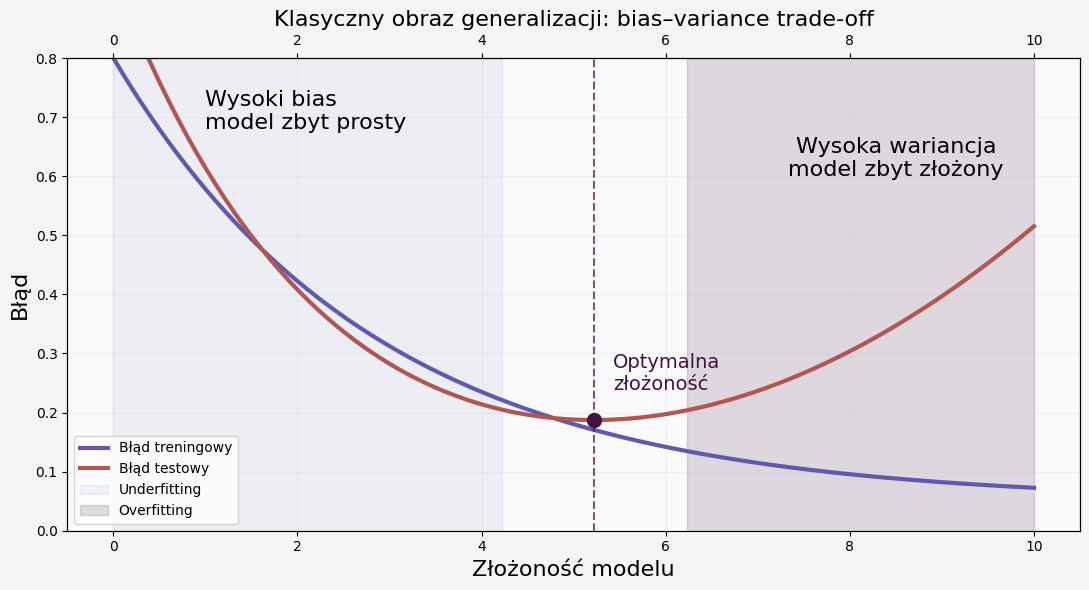

In [21]:
PALETTE = "twilight_shifted"
cmap = plt.get_cmap(PALETTE)

train_color = cmap(0.20)
test_color = cmap(0.75)
best_color = cmap(0.95)

fig, ax = plt.subplots(
    figsize=(11, 6)
)


fig.patch.set_facecolor("#F5F5F5")
ax.set_facecolor("#FAFAFA")


ax.plot(
    complexity,
    train_error,
    label="Błąd treningowy",
    linewidth=3,
    color=train_color,

)

ax.plot(
    complexity,
    test_error,
    label="Błąd testowy",
    linewidth=3,
    color=test_color,

)

ax.scatter(
    best_complexity,
    best_error,
    color=best_color,
    s=100,
    zorder=5,
)

ax.axvline(
    best_complexity,
    color=best_color,
    linestyle="--",
    alpha=0.7,
)


ax.axvspan(
    complexity.min(),
    best_complexity - 1,
    color=train_color,
    alpha=0.08,
    label="Underfitting",
)

ax.axvspan(
    best_complexity + 1,
    complexity.max(),
    color=best_color,
    alpha=0.15, #delikatne
    label="Overfitting",
)



ax.text(
    1.0,
    0.68,
    "Wysoki bias\nmodel zbyt prosty",
    fontsize=16,
    ha="left",
)

ax.text(
    8.5,
    0.60,
    "Wysoka wariancja\nmodel zbyt złożony",
    fontsize=16,
    ha="center",
)

ax.text(
    best_complexity + 0.2,
    best_error + 0.05,
    "Optymalna\nzłożoność",
    fontsize=14,
    color=best_color,
)

ax.set_xlabel(
    "Złożoność modelu",
    fontsize=16,
)

ax.set_ylabel(
    "Błąd",
    fontsize=16,
)

ax.set_title(
    "Klasyczny obraz generalizacji: bias–variance trade-off",
    fontsize=16,
)

# ZAKRESY OSI
ax.set_ylim(0, 0.8)
ax.grid(alpha=0.1)
ax.legend()
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
plt.tight_layout()

plt.show()

Przy małej złożoności model jest zbyt prosty, tu występuje underfitting i wysoki bias. Wraz ze wzrostem złożoności wynik na zbiorze testowym się poprawia. Po przekroczeniu pewnego punktu model zaczyna jednak dopasowywać się do szumu w danych więc rośnie wariancja i pojawia się overfitting.



Współczesne sieci neuronowe często mają jednak znacznie więcej parametrów niż próbek, osiągają niemal zerowy błąd treningowy, a mimo to generalizują dobrze. Artykuł bada, jak połączyć te dwa obrazy.

Główne pytania:

- Co dzieje się z błędem testowym przy zwiększaniu **rozmiaru modelu**?
- Co dzieje się przy zwiększaniu **liczby epok**?
- Czy zwiększanie **liczby danych** zawsze pomaga?
- Czy te osie można opisać wspólnym pojęciem złożoności całej procedury uczenia?

# 2. Klasyczna krzywa U i double descent

Klasyczny rozkład ryzyka zapisuje się schematycznie jako
$$
\begin{aligned}
R_{\mathrm{test}}(c)
&\approx \operatorname{Bias}^2(c)
 + \operatorname{Variance}(c)
 + \sigma^2.
\end{aligned}
$$

W obrazie double descent wyróżniamy trzy reżimy:

| Reżim | Charakterystyka | Typowe zachowanie |
|---|---|---|
| niedoparametryzowany | model nie interpoluje danych | klasyczny spadek, potem wzrost |
| krytyczny | procedura ledwie osiąga prawie zerowy train error | maksimum i wysoka niestabilność |
| nadparametryzowany | istnieje wiele rozwiązań interpolujących | drugi spadek błędu testowego |

W głębokiej sieci próg interpolacji nie musi pokrywać się z prostym warunkiem „liczba parametrów = liczba próbek”. Zależy także od optymalizatora, liczby kroków, augmentacji, regularyzacji i szumu etykiet.

# 3. Effective Model Complexity

Procedura uczenia $\mathcal{T}$ przyjmuje zbiór treningowy $S$ i zwraca wytrenowany model $\mathcal{T}(S)$.

Autorzy definiują

$$
\operatorname{EMC}_{\mathcal{D},\varepsilon}(\mathcal{T})
=
\max\left\{
n \;\middle|\;
\mathbb{E}_{S\sim\mathcal{D}^{n}}
\left[
\operatorname{Error}_{S}\bigl(\mathcal{T}(S)\bigr)
\right]
\leq \varepsilon
\right\}.
$$

EMC jest największą liczbą próbek, dla której dana **cała procedura** osiąga średnio błąd treningowy nie większy niż $\varepsilon$. W artykule stosowano heurystycznie $\varepsilon=0.1$.

EMC zależy nie tylko od architektury, lecz również od:

- rozkładu wejść i etykiet,
- optymalizatora,
- harmonogramu learning rate,
- czasu uczenia,
- augmentacji,
- regularyzacji,
- poziomu szumu etykiet.

Dlatego większa liczba epok może zwiększać efektywną złożoność bez zmiany nominalnej liczby parametrów.

# 4. Uogólniona hipoteza double descent

Dla zbioru o liczności \(n\):

- gdy $\mathrm{EMC}\ll n$, zwiększenie złożoności zwykle pomaga;
- gdy $\mathrm{EMC}\approx n$, zachowanie może być niemonotoniczne i niestabilne;
- gdy $\mathrm{EMC}\gg n$, dalsze zwiększanie złożoności często ponownie pomaga.

Hipoteza jest jakościowa. Autorzy nie podają uniwersalnego sposobu wyboru $\varepsilon$ ani szerokości obszaru krytycznego. Jej wartość polega na wskazaniu, że trzeba lokalizować próg interpolacji i sprawdzać, czy maksimum ryzyka przesuwa się wraz z tym progiem.

# 5. Metodologia artykułu


### Model-wise double descent
Ustalany jest długi czas uczenia, a zmieniany jest rozmiar modelu. Błąd testowy zestawia się z błędem treningowym, aby zlokalizować początek interpolacji.

### Epoch-wise double descent
Architektura jest stała, a analizowane są kolejne checkpointy. W dużym modelu test error może: maleć → rosnąć przy interpolacji → ponownie maleć.

### Sample-wise non-monotonicity
Model i procedura są stałe, a zmieniana jest liczba próbek. Więcej danych obniża ogólny poziom ryzyka, ale przesuwa próg interpolacji; lokalnie ten drugi efekt może dominować.

## 5.2. Zbiory, architektury i metryki

| Zadanie | Dane | Architektura | Metryka |
|---|---|---|---|
| klasyfikacja | CIFAR-10 | ResNet18, 5-layer CNN | classification error |
| klasyfikacja | CIFAR-100 | ResNet18, 5-layer CNN | classification error |
| tłumaczenie de→en | IWSLT'14 | Transformer | loss / perplexity |
| tłumaczenie en→fr | WMT'14 | Transformer | loss / perplexity |

### Rodzina ResNet18
Pre-activation ResNet18, cztery bloki, po dwie warstwy BatchNorm–ReLU–Conv. Szerokości: $[k,2k,4k,8k]$, stride: $[1,2,2,2]$. Standardowy ResNet18 odpowiada $k=64$.

### Pięciowarstwowy CNN
Cztery bloki Conv–BatchNorm–ReLU–MaxPool i warstwa fully connected. Szerokości: $[k,2k,4k,8k]$. Pooling: $[1,2,2,8]$. Kernel $3$, stride $1$, padding $1$.

### Transformer
Encoder–decoder, 6 warstw, 8 głów attention, zmieniany $d_{\mathrm{model}}$, a $d_{\mathrm{ff}}=4d_{\mathrm{model}}$.

## 5.3. Optymalizacja, augmentacja i szum

### Klasyfikacja obrazów

- cross-entropy;
- batch size 128;
- domyślna inicjalizacja PyTorch;
- brak weight decay i dropout, o ile nie zaznaczono inaczej;
- Adam: stały learning rate $10^{-4}$, do 4000 epok;
- SGD: początkowo $0.1$, brak momentum, inverse-square-root schedule, do 500 000 kroków.

Augmentacja CIFAR:

- `RandomCrop(32, padding=4)`;
- `RandomHorizontalFlip`.

### Transformer

- 80 000 kroków;
- 10% label smoothing;
- bez dropout;
- warmup, potem inverse-square-root decay;
- BPE i fairseq.

### Szum etykiet

Dla prawdopodobieństwa \(p\) poprawna etykieta jest zastępowana jednostajnie wybraną **niepoprawną** klasą. Szum losuje się raz, nie w każdej epoce. Wszystkie augmentacje danego obrazu mają tę samą zaszumioną etykietę.

## 5.4. Najważniejszy test spójności

Manipulacje zwiększające trudność interpolacji powinny przesuwać maksimum test error w stronę większej EMC:

| Manipulacja | Oczekiwany skutek |
|---|---|
| większy szum etykiet | maksimum przy większym modelu / późniejszej epoce |
| augmentacja | próg przesuwa się ku większym modelom |
| więcej próbek | próg przesuwa się ku większym modelom |
| dłuższy trening | rośnie EMC, model przechodzi przez próg |
| regularyzacja | maksimum może się przesunąć lub wygładzić |

To systematyczne przesuwanie maksimum jest mocniejszym argumentem niż pojedyncza niemonotoniczna krzywa.

## Środowisko eksperymentalne

In [22]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 2026
np.set_printoptions(precision=4, suppress=True)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.13
NumPy: 2.0.2
pandas: 2.2.2
scikit-learn: 1.6.1


# 8. Wizualizacja pojęciowa

Poniższy wykres jest wyłącznie schematem. Nie stanowi wyniku eksperymentalnego.

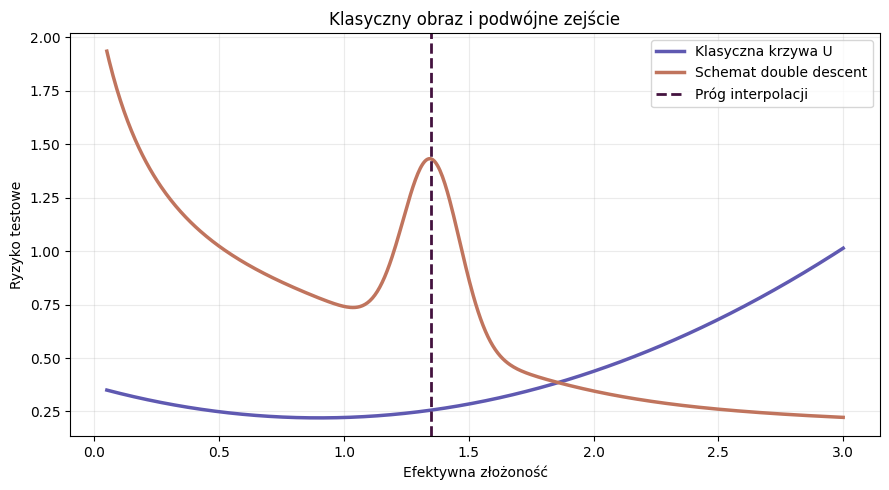

In [23]:
complexity = np.linspace(0.05, 3.0, 600)

classical = 0.22 + 0.18 * (complexity - 0.9) ** 2
double_descent = (
    0.26
    + 0.45 / (complexity + 0.25)
    + 0.85 * np.exp(-((complexity - 1.35) / 0.16) ** 2)
    - 0.18 * np.tanh(1.5 * (complexity - 1.5))
)

cmap = plt.get_cmap(PALETTE)

classical_color = cmap(0.20)
double_color = cmap(0.70)
threshold_color = cmap(0.95)


fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    complexity,
    classical,
    label="Klasyczna krzywa U",
    color=classical_color,
    linewidth=2.5
)

ax.plot(
    complexity,
    double_descent,
    label="Schemat double descent",
    color=double_color,
    linewidth=2.5
)

ax.axvline(
    1.35,
    linestyle="--",
    color=threshold_color,
    linewidth=2,
    label="Próg interpolacji"
)

ax.set_xlabel("Efektywna złożoność")
ax.set_ylabel("Ryzyko testowe")

ax.set_title(
    "Klasyczny obraz i podwójne zejście"
)

ax.legend()

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

# model-wise double descent w regresji liniowej

Generujemy

$$
y=X\beta^\star+\varepsilon,\qquad \varepsilon\sim\mathcal{N}(0,\sigma^2I),
$$

a dla każdej liczby cech $p$ wyznaczamy rozwiązanie najmniejszej normy

$$
\widehat{\beta}_p=X_p^+y.
$$

Przy $p<n$ jest to klasyczne least squares. Przy $p\ge n$ otrzymujemy interpolujące rozwiązanie minimum-norm. Oczekujemy maksimum blisko $p=n$.

In [24]:
def simulate_modelwise(
    seed=SEED,
    n_train=120,
    n_test=2500,
    d_max=300,
    noise_std=0.5,
    trials=25,
):
    rng = np.random.default_rng(seed)
    p_grid = np.unique(
        np.r_[np.arange(5, 91, 10),
              np.arange(95, 146, 5),
              np.arange(160, 301, 20)]
    ).astype(int)

    beta = np.exp(-np.arange(d_max) / 45.0)
    beta = beta / np.linalg.norm(beta) * 5.0
    rows = []

    for trial in range(trials):
        Xtr = rng.normal(size=(n_train, d_max)) / np.sqrt(d_max)
        Xte = rng.normal(size=(n_test, d_max)) / np.sqrt(d_max)
        ytr = Xtr @ beta + rng.normal(scale=noise_std, size=n_train)
        yte = Xte @ beta + rng.normal(scale=noise_std, size=n_test)

        for p in p_grid:
            coef = np.linalg.lstsq(Xtr[:, :p], ytr, rcond=None)[0]
            rows.append({
                "trial": trial,
                "p": p,
                "train_mse": np.mean((Xtr[:, :p] @ coef - ytr) ** 2),
                "test_mse": np.mean((Xte[:, :p] @ coef - yte) ** 2),
            })

    raw = pd.DataFrame(rows)
    summary = raw.groupby("p").agg(
        train_mse=("train_mse", "mean"),
        test_median=("test_mse", "median"),
        q25=("test_mse", lambda x: x.quantile(0.25)),
        q75=("test_mse", lambda x: x.quantile(0.75)),
        test_mean=("test_mse", "mean"),
    ).reset_index()
    return raw, summary

modelwise_raw, modelwise = simulate_modelwise()
modelwise.head()

,p,train_mse,test_median,q25,q75,test_mean
0,5,0.299089,0.331058,0.326938,0.337846,0.334891
1,15,0.256924,0.332975,0.326868,0.342293,0.336628
2,25,0.217946,0.359537,0.334528,0.379533,0.355312
3,35,0.187338,0.386711,0.363671,0.406814,0.390513
4,45,0.163594,0.416805,0.399810,0.439015,0.424944


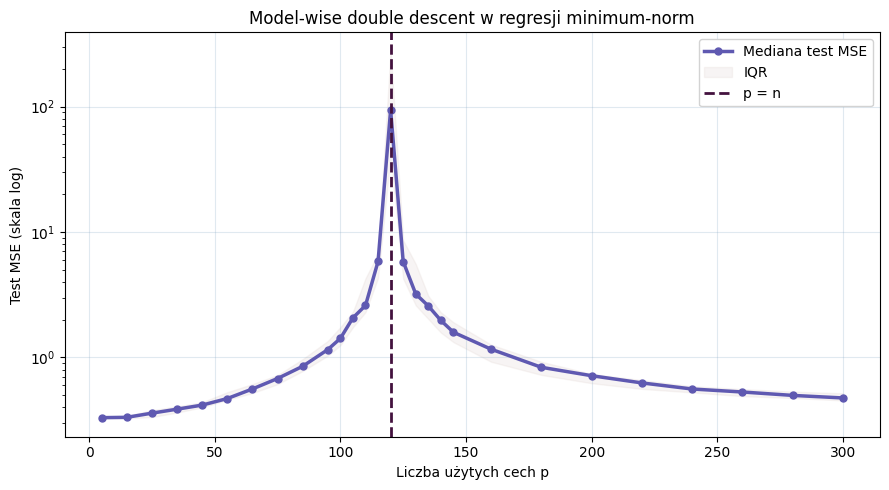

In [35]:
cmap = plt.get_cmap(PALETTE)

median_color = cmap(0.20)
iqr_color = cmap(0.55)
threshold_color = cmap(0.95)
grid_color = cmap(0.35)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    modelwise["p"],
    modelwise["test_median"],
    marker="o",
    color=median_color,
    linewidth=2.5,
    markersize=5,
    label="Mediana test MSE"
)

ax.fill_between(
    modelwise["p"],
    modelwise["q25"],
    modelwise["q75"],
    color=iqr_color,
    alpha=0.20,
    label="IQR"
)

ax.axvline(
    120,
    linestyle="--",
    color=threshold_color,
    linewidth=2,
    label="p = n"
)

ax.set_yscale("log")
ax.set_xlabel("Liczba użytych cech p")
ax.set_ylabel("Test MSE (skala log)")
ax.set_title("Model-wise double descent w regresji minimum-norm")

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor="lightgray"
)

ax.grid(
    alpha=0.25,
    color=grid_color
)

plt.tight_layout()
plt.show()

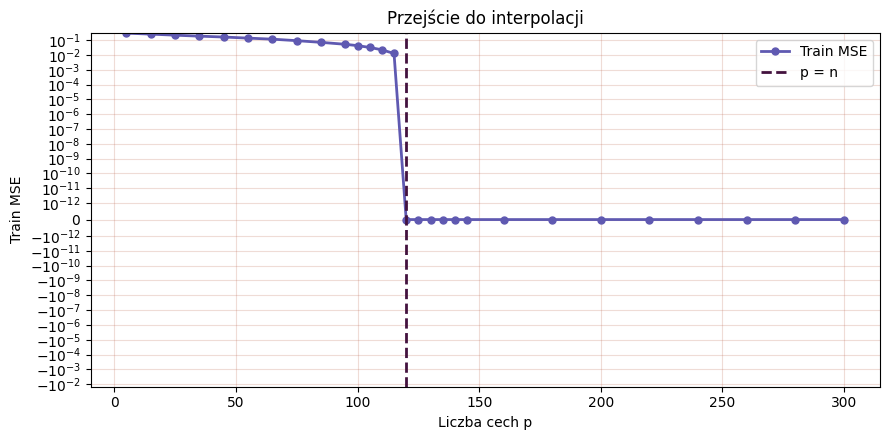

Maksimum mediany test MSE: 120
Pierwszy praktycznie interpolujący punkt: 120


In [36]:
cmap = plt.get_cmap(PALETTE)

classical_color = cmap(0.20)
double_color = cmap(0.70)
threshold_color = cmap(0.95)


fig, ax = plt.subplots(figsize=(9, 4.5))

# Train MSE
ax.plot(
    modelwise["p"],
    modelwise["train_mse"],
    marker="o",
    color=classical_color,
    linewidth=2,
    markersize=5,
    label="Train MSE"
)

# Próg interpolacji p = n
ax.axvline(
    120,
    linestyle="--",
    color=threshold_color,
    linewidth=2,
    label="p = n"
)

ax.set_yscale(
    "symlog",
    linthresh=1e-12
)

ax.set_xlabel("Liczba cech p")
ax.set_ylabel("Train MSE")
ax.set_title("Przejście do interpolacji")

ax.legend()

ax.grid(
    alpha=0.25,
    color=double_color
)

plt.tight_layout()
plt.show()


peak_p = int(
    modelwise.loc[
        modelwise["test_median"].idxmax(),
        "p"
    ]
)

first_interp = int(
    modelwise.loc[
        modelwise["train_mse"] < 1e-10,
        "p"
    ].min()
)

print("Maksimum mediany test MSE:", peak_p)
print("Pierwszy praktycznie interpolujący punkt:", first_interp)

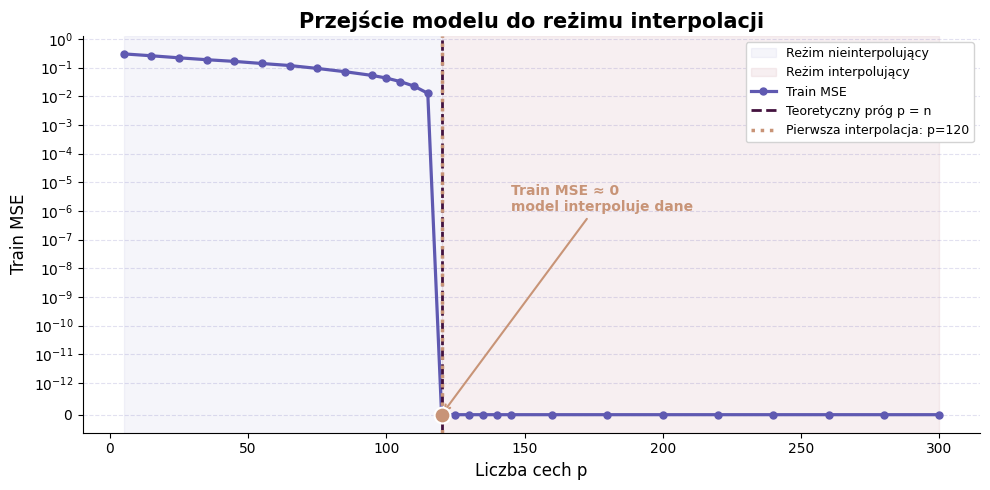

Maksimum mediany test MSE: 120
Pierwszy praktycznie interpolujący punkt: 120


In [37]:
cmap = plt.get_cmap(PALETTE)

curve_color = cmap(0.20)
interp_color = cmap(0.65)
threshold_color = cmap(0.95)
shade_color = cmap(0.80)

peak_p = int(
    modelwise.loc[
        modelwise["test_median"].idxmax(),
        "p"
    ]
)

first_interp = int(
    modelwise.loc[
        modelwise["train_mse"] < 1e-10,
        "p"
    ].min()
)

interp_mse = modelwise.loc[
    modelwise["p"] == first_interp,
    "train_mse"
].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5))

ax.axvspan(
    modelwise["p"].min(),
    first_interp,
    color=curve_color,
    alpha=0.06,
    label="Reżim nieinterpolujący"
)

ax.axvspan(
    first_interp,
    modelwise["p"].max(),
    color=shade_color,
    alpha=0.08,
    label="Reżim interpolujący"
)

ax.plot(
    modelwise["p"],
    modelwise["train_mse"],
    marker="o",
    markersize=5,
    linewidth=2.3,
    color=curve_color,
    label="Train MSE"
)

ax.axvline(
    120,
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="Teoretyczny próg p = n"
)

ax.axvline(
    first_interp,
    linestyle=":",
    linewidth=2.5,
    color=interp_color,
    label=f"Pierwsza interpolacja: p={first_interp}"
)

ax.scatter(
    first_interp,
    interp_mse,
    s=130,
    color=interp_color,
    edgecolor="white",
    linewidth=1.5,
    zorder=5
)

ax.annotate(
    "Train MSE ≈ 0\nmodel interpoluje dane",
    xy=(first_interp, interp_mse),
    xytext=(first_interp + 25, 1e-6),
    arrowprops=dict(
        arrowstyle="->",
        color=interp_color,
        linewidth=1.5
    ),
    color=interp_color,
    fontsize=10,
    fontweight="bold"
)

ax.set_yscale("symlog", linthresh=1e-12)

ax.set_xlabel("Liczba cech p", fontsize=12)
ax.set_ylabel("Train MSE", fontsize=12)
ax.set_title("Przejście modelu do reżimu interpolacji", fontsize=15, fontweight="bold")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.18,
    color=curve_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor="lightgray",
    fontsize=9,
    loc="upper right"
)

plt.tight_layout()
plt.show()

print("Maksimum mediany test MSE:", peak_p)
print("Pierwszy praktycznie interpolujący punkt:", first_interp)

### Interpretacja

Przed progiem błąd treningowy maleje. W pobliżu $p=n$ układ jest źle uwarunkowany i silnie wzmacnia szum. Po przejściu do reżimu nadparametryzowanego rozwiązanie minimum-norm ponownie poprawia generalizację.

W tym kontrolowanym modelu liniowym próg jest bliski $p=n$. W sieci głębokiej należy lokalizować go empirycznie.

# Wpływ poziomu szumu

W artykule szum etykiet zwykle wzmacnia maksimum. W regresji analogiczną rolę odgrywa wariancja szumu obserwacyjnego.

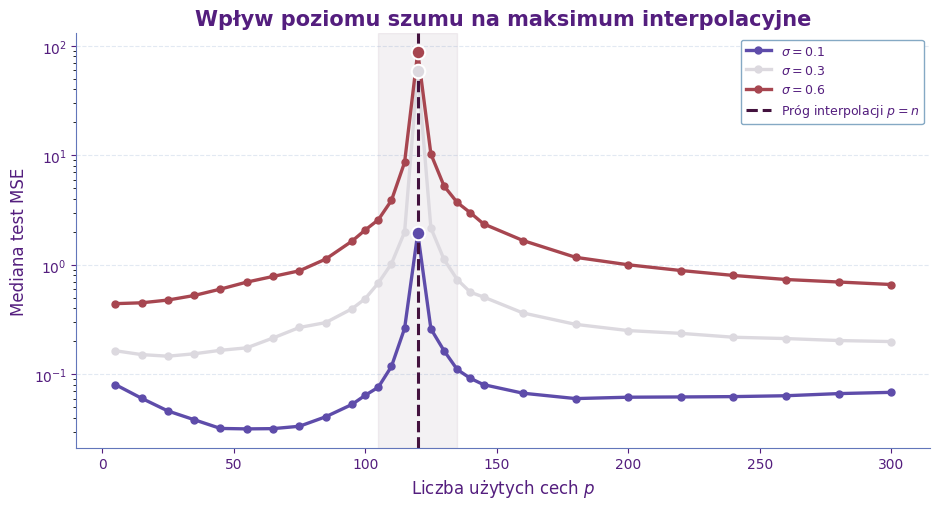

In [40]:
noise_parts = []

for i, sigma in enumerate([0.1, 0.3, 0.6]):
    _, summary = simulate_modelwise(
        seed=SEED + 100 * i,
        noise_std=sigma,
        trials=14,
    )

    part = summary[["p", "test_median"]].copy()
    part["sigma"] = sigma
    noise_parts.append(part)

noise_results = pd.concat(noise_parts, ignore_index=True)


cmap = plt.get_cmap(PALETTE)

sigmas = sorted(noise_results["sigma"].unique())
colors = cmap(np.linspace(0.18, 0.78, len(sigmas)))

threshold_color = cmap(0.95)
grid_color = cmap(0.30)
text_color = cmap(0.10)
spine_color = cmap(0.25)
legend_edge_color = cmap(0.35)


fig, ax = plt.subplots(figsize=(9.5, 5.2))

for color, sigma in zip(colors, sigmas):
    group = noise_results[
        noise_results["sigma"] == sigma
    ].sort_values("p")

    ax.plot(
        group["p"],
        group["test_median"],
        marker="o",
        markersize=5,
        linewidth=2.4,
        color=color,
        label=fr"$\sigma={sigma}$"
    )

    peak_idx = group["test_median"].idxmax()
    peak_p = group.loc[peak_idx, "p"]
    peak_mse = group.loc[peak_idx, "test_median"]

    ax.scatter(
        peak_p,
        peak_mse,
        s=95,
        color=color,
        edgecolor="white",
        linewidth=1.5,
        zorder=5
    )

ax.axvspan(
    105,
    135,
    color=threshold_color,
    alpha=0.06
)

ax.axvline(
    120,
    linestyle="--",
    linewidth=2.2,
    color=threshold_color,
    label=r"Próg interpolacji $p=n$"
)

ax.text(
    120,
    ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 1,
    "",
)

ax.set_yscale("log")

ax.set_xlabel(
    "Liczba użytych cech $p$",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Mediana test MSE",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Wpływ poziomu szumu na maksimum interpolacyjne",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color,
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.20,
    color=grid_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(spine_color)
ax.spines["bottom"].set_color(spine_color)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor=legend_edge_color,
    labelcolor=text_color,
    fontsize=9,
    loc="best"
)

plt.tight_layout()
plt.show()

# Losowe cechy ReLU

Budujemy zamrożoną losową reprezentację

$$
z_j(x)=\max(0,w_j^\top x+b_j),
$$
a uczymy tylko warstwę liniową. Liczba cech $m$ jest analogiem szerokości. Używamy `make_moons`, 200 próbek treningowych i 15% jednorazowo odwróconych etykiet.

In [41]:
def random_relu_experiment(
    seed=SEED,
    n_train=200,
    n_test=2000,
    label_noise=0.15,
    trials=12,
):
    rng = np.random.default_rng(seed)
    m_grid = np.unique(
        np.r_[np.arange(5, 101, 10),
              np.arange(110, 251, 10),
              np.arange(280, 501, 40)]
    ).astype(int)
    rows = []

    for trial in range(trials):
        X, y = make_moons(
            n_samples=n_train + n_test,
            noise=0.20,
            random_state=seed + trial,
        )
        Xtr, Xte, ytr, yte = train_test_split(
            X, y, train_size=n_train,
            random_state=seed + trial, stratify=y,
        )
        scaler = StandardScaler().fit(Xtr)
        Xtr = scaler.transform(Xtr)
        Xte = scaler.transform(Xte)

        ynoisy = ytr.copy()
        flip = rng.choice(n_train, size=int(label_noise * n_train), replace=False)
        ynoisy[flip] = 1 - ynoisy[flip]

        mmax = int(m_grid.max())
        W = rng.normal(size=(2, mmax))
        b = rng.normal(size=mmax)
        Ztr = np.maximum(0.0, Xtr @ W + b)
        Zte = np.maximum(0.0, Xte @ W + b)
        target = 2 * ynoisy - 1

        for m in m_grid:
            Atr = np.c_[np.ones(n_train), Ztr[:, :m]]
            Ate = np.c_[np.ones(n_test), Zte[:, :m]]
            coef = np.linalg.lstsq(Atr, target, rcond=None)[0]
            pred_tr = (Atr @ coef > 0).astype(int)
            pred_te = (Ate @ coef > 0).astype(int)
            rows.append({
                "trial": trial,
                "m": m,
                "train_error": 1 - np.mean(pred_tr == ynoisy),
                "test_error": 1 - np.mean(pred_te == yte),
            })

    raw = pd.DataFrame(rows)
    summary = raw.groupby("m").agg(
        train_error=("train_error", "median"),
        test_error=("test_error", "median"),
        q25=("test_error", lambda x: x.quantile(0.25)),
        q75=("test_error", lambda x: x.quantile(0.75)),
    ).reset_index()
    return raw, summary

relu_raw, relu_summary = random_relu_experiment()
relu_summary.head()

,m,train_error,test_error,q25,q75
0,5,0.2425,0.1290,0.125375,0.177625
1,15,0.1775,0.0830,0.065625,0.102625
2,25,0.1650,0.0895,0.067625,0.095625
3,35,0.1500,0.0895,0.076875,0.097375
4,45,0.1425,0.1030,0.089375,0.123250


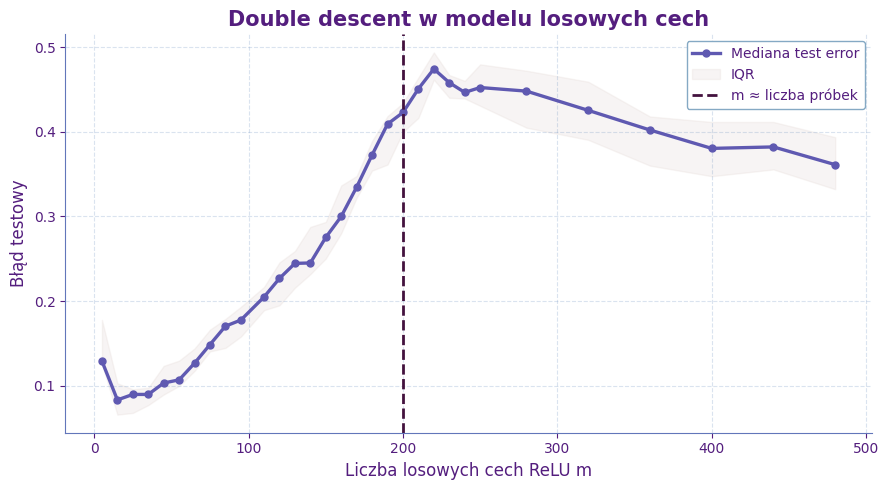

In [42]:
cmap = plt.get_cmap(PALETTE)

curve_color = cmap(0.20)
band_color = cmap(0.55)
threshold_color = cmap(0.95)
grid_color = cmap(0.30)
text_color = cmap(0.10)
spine_color = cmap(0.25)
legend_edge_color = cmap(0.35)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    relu_summary["m"],
    relu_summary["test_error"],
    marker="o",
    markersize=5,
    linewidth=2.4,
    color=curve_color,
    label="Mediana test error"
)

ax.fill_between(
    relu_summary["m"],
    relu_summary["q25"],
    relu_summary["q75"],
    color=band_color,
    alpha=0.20,
    label="IQR"
)

ax.axvline(
    200,
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="m ≈ liczba próbek"
)

ax.set_xlabel(
    "Liczba losowych cech ReLU m",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Błąd testowy",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Double descent w modelu losowych cech",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color,
    labelsize=10
)

ax.grid(
    alpha=0.25,
    linestyle="--",
    color=grid_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(spine_color)
ax.spines["bottom"].set_color(spine_color)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor=legend_edge_color,
    labelcolor=text_color
)

plt.tight_layout()
plt.show()

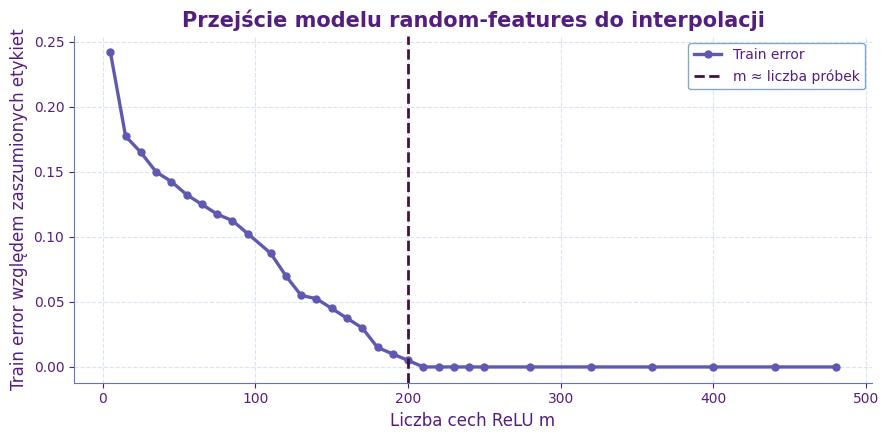

In [43]:
cmap = plt.get_cmap(PALETTE)

curve_color = cmap(0.20)
threshold_color = cmap(0.95)
grid_color = cmap(0.30)
text_color = cmap(0.10)
spine_color = cmap(0.25)
legend_edge_color = cmap(0.35)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    relu_summary["m"],
    relu_summary["train_error"],
    marker="o",
    markersize=5,
    linewidth=2.4,
    color=curve_color,
    label="Train error"
)

ax.axvline(
    200,
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="m ≈ liczba próbek"
)

ax.set_xlabel(
    "Liczba cech ReLU m",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Train error względem zaszumionych etykiet",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Przejście modelu random-features do interpolacji",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color,
    labelsize=10
)

ax.grid(
    alpha=0.25,
    linestyle="--",
    color=grid_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(spine_color)
ax.spines["bottom"].set_color(spine_color)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor=legend_edge_color,
    labelcolor=text_color
)

plt.tight_layout()
plt.show()

Model losowych cech jest pomostem między regresją liniową a siecią neuronową: reprezentacja jest nieliniowa, lecz optymalizacja ostatniej warstwy pozostaje dokładnie kontrolowalna.

# Sample-wise non-monotonicity


Ustalamy $p=120$ i zwiększamy $n$. W reżimie $n<p$ rozwiązanie minimum-norm interpoluje dane. Gdy $n$ zbliża się do $p$, wariancja może wzrosnąć tak silnie, że dodatkowe próbki lokalnie pogarszają wynik.

In [45]:
def simulate_samplewise(
    seed=SEED + 1,
    p=120,
    n_test=3000,
    noise_std=0.5,
    trials=25,
):
    rng = np.random.default_rng(seed)
    n_grid = np.unique(
        np.r_[np.arange(20, 91, 10),
              np.arange(95, 146, 5),
              np.arange(160, 261, 20)]
    ).astype(int)

    beta = np.exp(-np.arange(p) / 35.0)
    beta = beta / np.linalg.norm(beta) * 5.0
    Xte = rng.normal(size=(n_test, p)) / np.sqrt(p)
    yte = Xte @ beta
    rows = []

    for trial in range(trials):
        for n in n_grid:
            Xtr = rng.normal(size=(n, p)) / np.sqrt(p)
            ytr = Xtr @ beta + rng.normal(scale=noise_std, size=n)
            coef = np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
            rows.append({
                "trial": trial,
                "n": n,
                "train_mse": np.mean((Xtr @ coef - ytr) ** 2),
                "test_mse": np.mean((Xte @ coef - yte) ** 2),
            })

    raw = pd.DataFrame(rows)
    summary = raw.groupby("n").agg(
        train_mse=("train_mse", "mean"),
        test_median=("test_mse", "median"),
        q25=("test_mse", lambda x: x.quantile(0.25)),
        q75=("test_mse", lambda x: x.quantile(0.75)),
    ).reset_index()
    return raw, summary

samplewise_raw, samplewise = simulate_samplewise()
samplewise.head()

,n,train_mse,test_median,q25,q75
0,20,1.843777e-30,0.224516,0.212910,0.236046
1,30,1.040637e-30,0.230933,0.213617,0.248667
2,40,1.942153e-30,0.280064,0.253681,0.298772
3,50,1.665677e-30,0.279488,0.263948,0.297462
4,60,2.027244e-30,0.347284,0.317109,0.396511


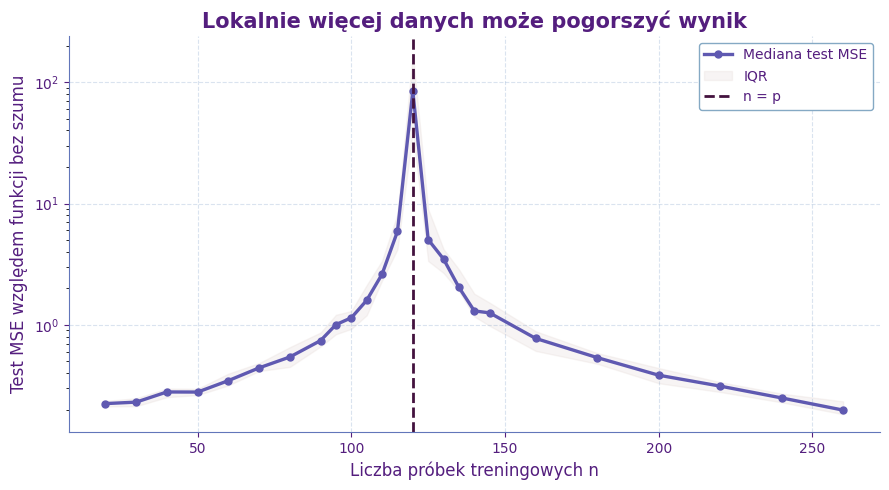

In [46]:
cmap = plt.get_cmap(PALETTE)

curve_color = cmap(0.20)
band_color = cmap(0.55)
threshold_color = cmap(0.95)
grid_color = cmap(0.30)
text_color = cmap(0.10)
spine_color = cmap(0.25)
legend_edge_color = cmap(0.35)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    samplewise["n"],
    samplewise["test_median"],
    marker="o",
    markersize=5,
    linewidth=2.4,
    color=curve_color,
    label="Mediana test MSE"
)

ax.fill_between(
    samplewise["n"],
    samplewise["q25"],
    samplewise["q75"],
    color=band_color,
    alpha=0.20,
    label="IQR"
)

ax.axvline(
    120,
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="n = p"
)

ax.set_yscale("log")

ax.set_xlabel(
    "Liczba próbek treningowych n",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Test MSE względem funkcji bez szumu",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Lokalnie więcej danych może pogorszyć wynik",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color,
    labelsize=10
)

ax.grid(
    alpha=0.25,
    linestyle="--",
    color=grid_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(spine_color)
ax.spines["bottom"].set_color(spine_color)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor=legend_edge_color,
    labelcolor=text_color
)

plt.tight_layout()
plt.show()

„Więcej danych szkodzi” dotyczy konkretnej, niezmienionej procedury estymacji. Nie oznacza, że informacja jest sama w sobie szkodliwa. Inna regularyzacja, strojenie albo early stopping może usunąć tę niemonotoniczność.

# Mapa pojemność × liczba próbek

Artykuł pokazuje „grzbiet” wysokiego ryzyka wzdłuż progu interpolacji. Poniżej odtwarzamy tę ideę dla regresji minimum-norm.

In [47]:
import seaborn as sns

cmap = sns.color_palette("twilight_shifted", as_cmap=True)

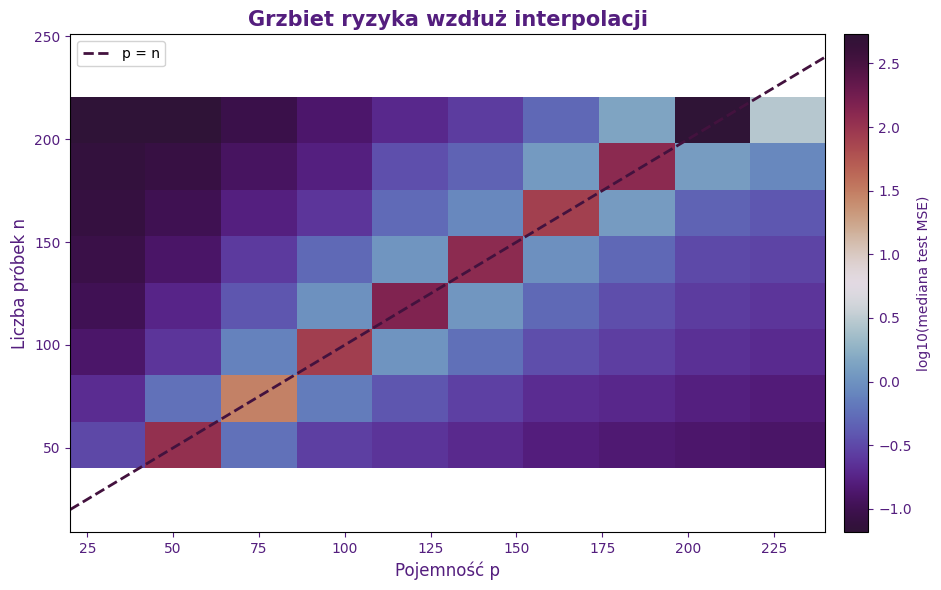

In [48]:
def capacity_sample_heatmap(
    seed=SEED + 4,
    trials=7,
    noise_std=0.5,
    d_max=240,
):
    rng = np.random.default_rng(seed)

    n_grid = np.array([40, 60, 80, 100, 120, 150, 180, 220])
    p_grid = np.array([20, 40, 60, 80, 100, 120, 150, 180, 220, 240])

    beta = np.exp(-np.arange(d_max) / 40.0)
    beta = beta / np.linalg.norm(beta) * 5.0

    rows = []

    for n in n_grid:
        for trial in range(trials):
            Xtr = rng.normal(size=(n, d_max)) / np.sqrt(d_max)
            Xte = rng.normal(size=(1600, d_max)) / np.sqrt(d_max)

            ytr = Xtr @ beta + rng.normal(
                scale=noise_std,
                size=n
            )

            yte = Xte @ beta

            for p in p_grid:
                coef = np.linalg.lstsq(
                    Xtr[:, :p],
                    ytr,
                    rcond=None
                )[0]

                rows.append({
                    "n": n,
                    "p": p,
                    "trial": trial,
                    "mse": np.mean(
                        (Xte[:, :p] @ coef - yte) ** 2
                    ),
                })

    raw = pd.DataFrame(rows)

    matrix = (
        raw
        .groupby(["n", "p"])["mse"]
        .median()
        .unstack()
    )

    return raw, matrix


heatmap_raw, heatmap_matrix = capacity_sample_heatmap()

cmap = sns.color_palette(
    "twilight_shifted",
    as_cmap=True
)

fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(
    np.log10(heatmap_matrix.values),
    origin="lower",
    aspect="auto",
    cmap=cmap,
    extent=[
        heatmap_matrix.columns.min(),
        heatmap_matrix.columns.max(),
        heatmap_matrix.index.min(),
        heatmap_matrix.index.max(),
    ]
)

threshold_color = plt.get_cmap(PALETTE)(0.95)
text_color = plt.get_cmap(PALETTE)(0.10)

ax.plot(
    [
        heatmap_matrix.columns.min(),
        heatmap_matrix.columns.max()
    ],
    [
        heatmap_matrix.columns.min(),
        heatmap_matrix.columns.max()
    ],
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="p = n"
)

ax.set_xlabel(
    "Pojemność p",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Liczba próbek n",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Grzbiet ryzyka wzdłuż interpolacji",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color
)

cbar = fig.colorbar(
    image,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "log10(mediana test MSE)",
    color=text_color
)

cbar.ax.tick_params(
    colors=text_color
)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor="lightgray"
)

plt.tight_layout()
plt.show()

Mapa dwuwymiarowa jest ważniejsza od pojedynczego piku, ponieważ pozwala sprawdzić, czy obszar wysokiego ryzyka systematycznie podąża za progiem po zmianie liczby próbek.

# Wpływ regularyzacji

Ridge:

$$
\widehat{\beta}_\alpha=(X^\top X+n\alpha I)^{-1}X^\top y
$$

tłumi kierunki związane z małymi wartościami singularnymi. Te kierunki odpowiadają za eksplozję wariancji przy interpolacji.

In [50]:
def ridge_experiment(
    seed=SEED + 8,
    n_train=120,
    n_test=2200,
    d_max=300,
    noise_std=0.5,
    trials=14,
    alphas=(0.0, 0.001, 0.01, 0.1),
):
    rng = np.random.default_rng(seed)
    p_grid = np.unique(
        np.r_[np.arange(10, 101, 10),
              np.arange(105, 141, 5),
              np.arange(160, 301, 20)]
    ).astype(int)

    beta = np.exp(-np.arange(d_max) / 45.0)
    beta = beta / np.linalg.norm(beta) * 5.0
    rows = []

    for trial in range(trials):
        Xtr = rng.normal(size=(n_train, d_max)) / np.sqrt(d_max)
        Xte = rng.normal(size=(n_test, d_max)) / np.sqrt(d_max)
        ytr = Xtr @ beta + rng.normal(scale=noise_std, size=n_train)
        yte = Xte @ beta

        for p in p_grid:
            U, s, Vt = np.linalg.svd(Xtr[:, :p], full_matrices=False)
            uy = U.T @ ytr

            for alpha in alphas:
                if alpha == 0.0:
                    filt = np.divide(1.0, s, out=np.zeros_like(s), where=s > 1e-12)
                else:
                    filt = s / (s**2 + n_train * alpha)
                coef = Vt.T @ (filt * uy)
                rows.append({
                    "trial": trial, "p": p, "alpha": alpha,
                    "test_mse": np.mean((Xte[:, :p] @ coef - yte) ** 2),
                })

    raw = pd.DataFrame(rows)
    summary = raw.groupby(["p", "alpha"])["test_mse"].median().reset_index()
    return raw, summary

ridge_raw, ridge_summary = ridge_experiment()








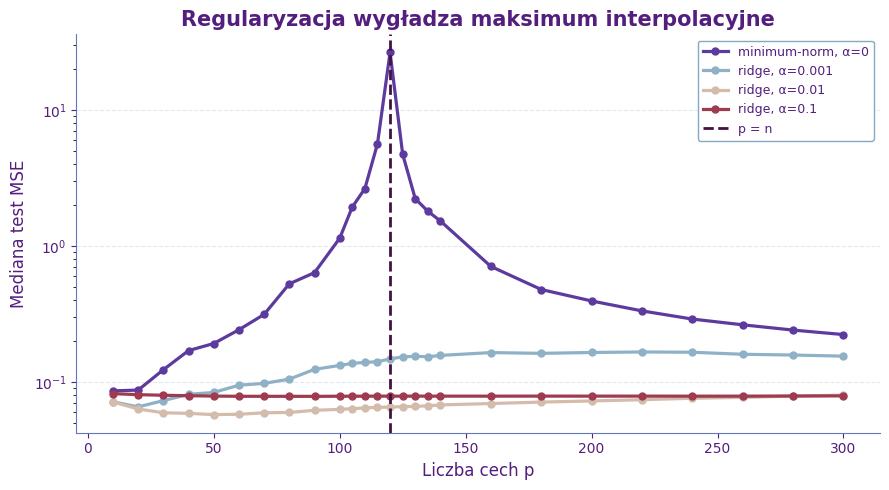

In [51]:
cmap = plt.get_cmap(PALETTE)

alphas = sorted(ridge_summary["alpha"].unique())
colors = cmap(np.linspace(0.15, 0.80, len(alphas)))

threshold_color = cmap(0.95)
grid_color = cmap(0.30)
text_color = cmap(0.10)
spine_color = cmap(0.25)
legend_edge_color = cmap(0.35)

fig, ax = plt.subplots(figsize=(9, 5))

for color, alpha in zip(colors, alphas):
    group = ridge_summary[
        ridge_summary["alpha"] == alpha
    ].sort_values("p")

    label = (
        "minimum-norm, α=0"
        if alpha == 0
        else f"ridge, α={alpha}"
    )

    ax.plot(
        group["p"],
        group["test_mse"],
        marker="o",
        markersize=5,
        linewidth=2.3,
        color=color,
        label=label
    )

ax.axvline(
    120,
    linestyle="--",
    linewidth=2,
    color=threshold_color,
    label="p = n"
)

ax.set_yscale("log")

ax.set_xlabel(
    "Liczba cech p",
    fontsize=12,
    color=text_color
)

ax.set_ylabel(
    "Mediana test MSE",
    fontsize=12,
    color=text_color
)

ax.set_title(
    "Regularyzacja wygładza maksimum interpolacyjne",
    fontsize=15,
    fontweight="bold",
    color=text_color
)

ax.tick_params(
    axis="both",
    colors=text_color,
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.20,
    color=grid_color
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(spine_color)
ax.spines["bottom"].set_color(spine_color)

ax.legend(
    facecolor="white",
    framealpha=1,
    edgecolor=legend_edge_color,
    labelcolor=text_color,
    fontsize=9
)

plt.tight_layout()
plt.show()

# Epoch-wise double descent
### kryteria interpretacji

Aby wykazać epoch-wise double descent, trzeba pokazać jednocześnie:

1. train error i moment interpolacji;
2. test error przed, przy i po tym momencie;
3. drugi spadek po maksimum;
4. kilka rozmiarów modeli:
   - mały, który nie interpoluje;
   - krytyczny, dla którego early stopping pomaga;
   - duży, który przechodzi pełną krzywą.

Samo zachowanie „spadek–wzrost” jest klasycznym przeuczeniem, nie pełnym podwójnym zejściem.

# repliki CIFAR-10

Kod poniżej odtwarza kluczowe elementy pięciowarstwowego CNN i konstrukcji szumu etykiet. Domyślnie nie uruchamia pobierania ani treningu.

In [ ]:
RUN_CIFAR_REPLICATION = True

if RUN_CIFAR_REPLICATION:
    import random
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, Dataset
    from torchvision import datasets, transforms

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    class NoisyLabelsDataset(Dataset):
        # Szum jest losowany raz i pozostaje stały przez cały trening.
        def __init__(self, base_dataset, num_classes, noise_probability, seed):
            self.base_dataset = base_dataset
            rng = np.random.default_rng(seed)
            original = np.asarray(base_dataset.targets, dtype=np.int64)
            noisy = original.copy()
            mask = rng.random(len(noisy)) < noise_probability
            offsets = rng.integers(1, num_classes, size=mask.sum())
            noisy[mask] = (noisy[mask] + offsets) % num_classes
            self.noisy_targets = noisy
            self.noise_mask = mask

        def __len__(self):
            return len(self.base_dataset)

        def __getitem__(self, index):
            image, _ = self.base_dataset[index]
            return image, int(self.noisy_targets[index])

    class ConvBlock(nn.Module):
        def __init__(self, in_channels, out_channels, pool_size):
            super().__init__()
            self.layers = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride=1, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(pool_size),
            )

        def forward(self, x):
            return self.layers(x)

    class FiveLayerCNN(nn.Module):
        def __init__(self, width, num_classes=10):
            super().__init__()
            k = int(width)
            self.features = nn.Sequential(
                ConvBlock(3, k, 1),
                ConvBlock(k, 2*k, 2),
                ConvBlock(2*k, 4*k, 2),
                ConvBlock(4*k, 8*k, 8),
            )
            self.classifier = nn.Linear(8*k, num_classes)

        def forward(self, x):
            x = self.features(x)
            return self.classifier(torch.flatten(x, 1))

    def evaluate(model, loader, criterion):
        model.eval()
        loss_sum = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                logits = model(images)
                loss = criterion(logits, labels)
                loss_sum += loss.item() * labels.size(0)
                correct += (logits.argmax(1) == labels).sum().item()
                total += labels.size(0)
        return {"loss": loss_sum / total, "error": 1 - correct / total}

    def train_configuration(
        width, train_loader, test_loader,
        epochs=4000, learning_rate=1e-4, seed=0, log_every=10
    ):
        torch.manual_seed(seed)
        np.random.seed(seed)
        random.seed(seed)

        model = FiveLayerCNN(width).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
        criterion = nn.CrossEntropyLoss()
        history = []

        for epoch in range(1, epochs + 1):
            model.train()
            loss_sum = 0.0
            correct = 0
            total = 0

            for images, labels in train_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                loss.backward()
                optimizer.step()

                loss_sum += loss.item() * labels.size(0)
                correct += (logits.argmax(1) == labels).sum().item()
                total += labels.size(0)

            if epoch == 1 or epoch % log_every == 0 or epoch == epochs:
                test = evaluate(model, test_loader, criterion)
                history.append({
                    "epoch": epoch,
                    "width": width,
                    "train_loss": loss_sum / total,
                    "train_error": 1 - correct / total,
                    "test_loss": test["loss"],
                    "test_error": test["error"],
                })

        return pd.DataFrame(history)

    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
    ])
    test_transform = transforms.ToTensor()

    clean_train = datasets.CIFAR10(
        "./data", train=True, download=True, transform=train_transform
    )
    test_dataset = datasets.CIFAR10(
        "./data", train=False, download=True, transform=test_transform
    )
    noisy_train = NoisyLabelsDataset(clean_train, 10, 0.15, SEED)

    train_loader = DataLoader(noisy_train, batch_size=128, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

    widths = [2, 4, 6, 8, 10, 12, 16, 20, 24, 32, 48, 64]
    histories = [
        train_configuration(
            width=w,
            train_loader=train_loader,
            test_loader=test_loader,
            epochs=4000,
            learning_rate=1e-4,
            seed=SEED + w,
        )
        for w in widths
    ]
    cifar_history = pd.concat(histories, ignore_index=True)
    cifar_history.to_csv("cifar_double_descent_history.csv", index=False)
else:
    print("Replika CIFAR wyłączona. Ustaw RUN_CIFAR_REPLICATION=True w środowisku z GPU.")

## Plan pełnej kampanii CIFAR

| Czynnik | Poziomy |
|---|---|
| szerokość \(k\) | gęsto wokół progu, rzadziej poza nim |
| szum etykiet | 0%, 10%, 20% |
| augmentacja | brak / crop+flip |
| optymalizator | Adam / SGD |
| seed | co najmniej 5 |
| checkpointy | gęsto na skali logarytmicznej |
| raport | final checkpoint i osobno early stopping |

Nie należy stroić learning rate osobno dla każdej szerokości, jeśli celem jest badanie jednej procedury \(\mathcal{T}\). Takie strojenie zmieniałoby procedurę wraz z rozmiarem.

# Przeniesienie metodologii do estymatorów funkcji score

Dla denoising score matching typowa strata ma postać

$$
\mathcal{L}(\theta)=
\mathbb{E}_{t,x_0,\varepsilon}
\left[
\lambda(t)
\left\|
s_\theta(x_t,t)-\nabla_{x_t}\log p(x_t\mid x_0)
\right\|_2^2
\right].
$$

Analogiczne osie badania:

### Capacity-wise
Szerokość, głębokość, liczba kanałów albo liczba parametrów sieci $s_\theta(x,t)$.

### Epoch-wise
Checkpointy tej samej architektury oraz train/validation score error w funkcji czasu.

### Sample-/perturbation-wise
- liczba czystych próbek;
- liczba perturbacji na próbkę;
- perturbacje stałe kontra resamplowane;
- niezależne perturbacje kontra pary antytetyczne.

## Operacyjna EMC dla score matching

Można zdefiniować

$$
\operatorname{EMC}^{\mathrm{score}}_{\varepsilon}(\mathcal{T})
=
\max\left\{
n:
\mathbb{E}
\left[
\widehat{\mathcal{L}}_{\mathrm{train}}(\mathcal{T}(S_n))
\right]
\le\varepsilon
\right\}.
$$

Ponieważ skala celu zależy od czasu $t$, lepiej używać straty znormalizowanej, a EMC szacować także osobno w przedziałach czasu. Pozwoli to sprawdzić, czy próg interpolacji dla małego szumu pojawia się w innym miejscu niż dla dużego szumu.

## Proponowana macierz eksperymentalna dla projektu

| Oś | Przykładowe poziomy |
|---|---|
| szerokość | 32, 64, 128, 256, 512 |
| głębokość | 2, 4, 6, 8 bloków |
| liczba czystych próbek | 1k, 2k, 5k, 10k |
| perturbacje / próbkę | 1, 2, 4, 8 |
| generator | stały, resampling, antytetyczny |
| czas uczenia | checkpointy logarytmiczne |
| seed | co najmniej 5 |

Najważniejsze wykresy:

1. train i validation score error vs pojemność;
2. heatmapa pojemność × kroki;
3. heatmapa pojemność × liczba próbek;
4. wynik vs $\mathrm{EMC}^{\mathrm{score}}/n$;
5. osobne krzywe dla przedziałów $t$;
6. mediany, IQR i pojedyncze seedy.

# uwaga: Ograniczenia interpretacyjne

- Double descent nie jest uniwersalnym prawem.
- Liczba parametrów nie jest pełną miarą pojemności.
- Wysoki pik może być wzmacniany przez problemy numeryczne.
- Final checkpoint i early stopping są różnymi procedurami.
- Test set nie może służyć do strojenia.
- Brak piku może wynikać ze zbyt rzadkiej siatki.
- Pik bez związku z interpolacją nie jest wystarczającym dowodem.
- Replikacja na modelu zastępczym nie zastępuje pełnej reprodukcji CIFAR/Transformer.


- [ ] Dokładnie zdefiniowana procedura $\mathcal{T}$
- [ ] Train loss i train error
- [ ] Gęsta siatka pojemności przy progu
- [ ] Jasne rozróżnienie szumu stałego i resamplowanego
- [ ] Budżet w krokach gradientowych
- [ ] Co najmniej kilka seedów
- [ ] Mediana, IQR i pojedyncze realizacje
- [ ] Final checkpoint oddzielony od early stopping
- [ ] Mapa 2D potwierdzająca przesuwanie się grzbietu
- [ ] Wyraźne rozróżnienie ilustracji i reprodukcji

Wnioski

Najważniejszym wkładem metodologicznym pracy jest powiązanie niemonotonicznego ryzyka z progiem interpolacji i potraktowanie złożoności jako własności całej procedury uczenia.
Dla estymatorów score naturalnym kolejnym krokiem jest badanie map pojemność × czas, pojemność × liczba próbek i pojemność × sposób generowania perturbacji.

# Bibliografia

1. Nakkiran, P. et al. *Deep double descent: where bigger models and more data hurt*. J. Stat. Mech. (2021) 124003. https://doi.org/10.1088/1742-5468/ac3a74
2. Preprint: https://arxiv.org/abs/1912.02292
3. Kod autorów: https://gitlab.com/harvard-machine-learning/double-descent
4. Belkin, M. et al. *Reconciling modern machine-learning practice and the classical bias–variance trade-off*. PNAS, 2019.
5. Hastie, T. et al. *Surprises in High-Dimensional Ridgeless Least Squares Interpolation*. 2019.
6. Nakkiran, P. *More Data Can Hurt for Linear Regression: Sample-wise Double Descent*. https://arxiv.org/abs/1912.07242
7. Nakkiran, P. et al. *Optimal Regularization Can Mitigate Double Descent*. https://arxiv.org/abs/2003.01897